In [5]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)
from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson

import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())
from matplotlib import font_manager
font_manager.fontManager.addfont("../../../../arial.ttf")
plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 18,
    "pdf.fonttype": 42,       # Embed TrueType fonts in PDF
})



/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


In [6]:
# real_data = sc.read_h5ad("../../input/plant_paper_day0_adata.h5ad")
real_data = sc.read_h5ad("../../input/plant_test_day21_data.h5ad")
print(real_data)
# print(data_2)

AnnData object with n_obs × n_vars = 12004 × 39337
    obs: 'n_genes', 'n_counts', 'Cluster', 'leiden_R', 'Cell type', 'Sample_time', 'Group'
    var: 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'mean', 'std', 'SNF', 'means_ForPickMock'
    uns: 'Cell type_colors'
    obsm: 'X_scvi', 'X_umap'
    layers: 'empty', 'normalize_log', 'raw'
    obsp: 'connectivities', 'distances'


In [7]:

predict_data = sc.read_h5ad("squidiff_exp0_interception_predict_day_21.h5ad")
# data = sc.read_h5ad("../input/plant_all_days.h5ad")
# print(print(adata[:5, :10].to_df()))
# Convert to dense numpy array regardless of sparse/dense format

X = predict_data.X
# print(X)
# X = data.X.toarray() if sp.issparse(data.X) else np.asarray(data.X)
# print(X.size)
# X = X.astype(np.float32)

print(X.shape)
print(X.shape[0] * X.shape[1])
total = X.shape[0] * X.shape[1]
print(total)
print("min:", np.min(X))
print("max:", np.max(X))
print("mean:", np.mean(X))
print("below 0:", np.sum(X < 0))
print("below 0:", np.sum(X < 0)/total)
print("below 0.1:", np.sum(X < 0.1))
print("below 0.1:", np.sum(X < 0.1)/total)

print("equals 0:", np.sum(X == 0))
print("equals 0:", np.sum(X == 0)/total)
print("below 18:", np.sum(X < 18))
print("below 18:", np.sum(X < 18)/total)
nan_count = np.isnan(X.data).sum()
print("nan:", nan_count)

(8229, 39337)
323704173
323704173
min: 0.0
max: 935.15784
mean: 62.806885
below 0: 0
below 0: 0.0
below 0.1: 161918227
below 0.1: 0.5002043239028617
equals 0: 161832395
equals 0: 0.4999391682232036
below 18: 176576678
below 18: 0.5454878025313563
nan: 0


r2,pearsonr: -198466.7530103566 -0.002444849955838051
66.5524 9.533525
66.5524 9.533525
max 66.5524


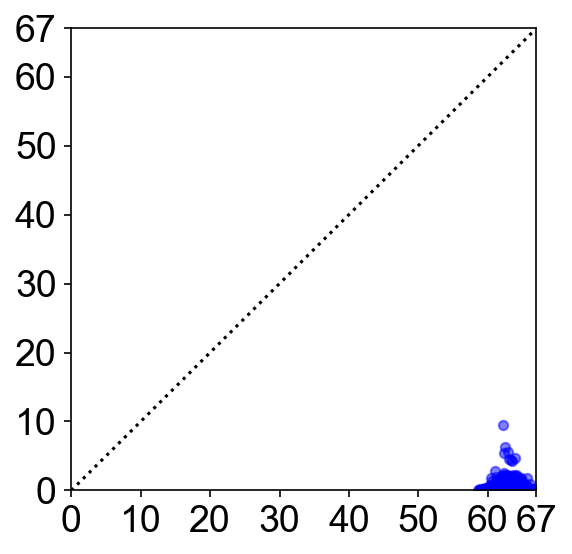

In [8]:

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
r_all = []
pearsonr_all = []
# print(predict_data)
# print(real_data)

# real_data_x = real_data.X if isinstance(real_data.X, np.ndarray) else real_data.X.toarray()
# real_data_tensor = torch.tensor(real_data_x, dtype=torch.float32)
# predict_data_x = predict_data.X if isinstance(predict_data.X, np.ndarray) else predict_data.X.toarray()
# predict_data_tensor = torch.tensor(predict_data_x, dtype=torch.float32)
# print(real_data_tensor.shape)
# print(predict_data_tensor.shape)
# print(real_data.shape)
# predict_data = sc.read_h5ad("../experiments/plants_experiment1_predict_day21_fixed/interception_predict_to_day_21.h5ad")
# real_data = sc.read_h5ad("../../inputs/plant_paper_test_day21_adata.h5ad")
r2, pearsonr,real,predict = calc_r2_pearson(real_data, predict_data)
print("r2,pearsonr:",r2, pearsonr)
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=150)
plt.scatter(predict,
            real,
            s=20,
            c='#0000FF',
            alpha=0.5
            
          )
limit = np.ceil(max(np.max(predict), np.max(real)))
print(np.max(predict),np.max(real))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  ticks = np.arange(0, limit + 1, 10)
else:    
  ticks = np.arange(0, limit + 1, 10)
    
ticks = np.append(ticks, limit)
ticks = np.unique(ticks)
plt.xticks(ticks)
plt.yticks(ticks)
print("max",max(np.max(predict), np.max(real)))
# plt.xlabel(f"Predicted mean expression")
# plt.ylabel(f"Actual mean expression")
# ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson $r$ = {pearsonr:.3f}",
#       transform=ax.transAxes, va="top", ha="left", fontsize=18, linespacing=1.4,
#       bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
fig.savefig(os.path.join(f"pred_day_21_exp0.pdf"), bbox_inches="tight")
  